# FireOutlook for July 15: how the forecast changed

Hold **July 15, 2026** fixed and follow seven evening forecast updates for
Wheeler County, Oregon, starting **July 8 at 8 p.m. PDT** and ending **July 14
at 8 p.m. PDT**. Every map targets the same period: **July 15 at 5 a.m. through
July 16 at 5 a.m. PDT**. This reproduces the sequence in the Wheeler County presentation.

Each daily issuance brings a new forecast for that fixed target, moving from
**Day 7 to Day 1**. This notebook uses the original July FireOutlook2.0 archive:
NBM for Days 7-2 and HRRR for Day 1. Longer leads are experimental.

The sample, county boundary, and five reported fire locations are bundled.
Install `outlook/requirements.txt`, then run all cells from the cloned repository.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

cwd = Path.cwd().resolve()
ROOT = next((base for parent in [cwd, *cwd.parents]
             for base in (parent / "outlook", parent)
             if (base / "examples" / "seven_day.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from within the cloned repository")
sys.path.insert(0, str(ROOT / "examples"))
from seven_day import (open_sample, schedule, select_update, plot_progression,
                       point_forecast, county_statistics, references, draw_update,
                       flag_names, LABELS)
ds = open_sample()
context = references()
output = ROOT / "outputs"
output.mkdir(exist_ok=True)
print("Forecast and reference checksums verified")
print("Product:", ds.attrs["product"])
print("Dimensions:", dict(ds.sizes))

Forecast and reference checksums verified
Product: FireOutlook2.0-hrrr1-nbm2to7-1
Dimensions: {'issue_time': 7, 'y': 576, 'x': 816}


## 1. One target date, seven updates

All times labeled PDT use Oregon local time. **July 8 at 8 p.m. PDT is July 9
at 03:00 UTC**, the first stored issuance covering the July 15 target at Day 7.
The July 8 **UTC** issuance reaches only July 14 at Day 7. Keeping both time
zones visible prevents shifting the sequence by a day.

In [2]:
timeline = schedule(ds)
display(timeline)
assert ds.complete.values.all()
assert timeline.issued_PDT.dt.day.tolist() == list(range(8, 15))
assert timeline.forecast_day.tolist() == list(range(7, 0, -1))
assert timeline.valid_start_PDT.nunique() == timeline.valid_end_PDT.nunique() == 1

,issued_PDT,issued_UTC,forecast_day,valid_start_PDT,valid_end_PDT,weather_cycle_UTC,weather_model,complete
0,2026-07-08 20:00:00-07:00,2026-07-09 03:00:00+00:00,7,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-09 00:00:00+00:00,NBM,True
1,2026-07-09 20:00:00-07:00,2026-07-10 03:00:00+00:00,6,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-10 00:00:00+00:00,NBM,True
2,2026-07-10 20:00:00-07:00,2026-07-11 03:00:00+00:00,5,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-11 00:00:00+00:00,NBM,True
3,2026-07-11 20:00:00-07:00,2026-07-12 03:00:00+00:00,4,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-12 00:00:00+00:00,NBM,True
4,2026-07-12 20:00:00-07:00,2026-07-13 03:00:00+00:00,3,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-13 00:00:00+00:00,NBM,True
5,2026-07-13 20:00:00-07:00,2026-07-14 03:00:00+00:00,2,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-14 00:00:00+00:00,NBM,True
6,2026-07-14 20:00:00-07:00,2026-07-15 03:00:00+00:00,1,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-15 00:00:00+00:00,HRRR,True


## 2. Compare the maps

The target period, map extent, and category colors stay the same in every panel.
The forecast values change with each issuance. Numbered points mark the five
reported fire origins. The July 16-17 observed outlines provide fixed reference
geography; they do not represent forecast fire boundaries.

Gray means unavailable. The maps use stored category codes and original
two-dimensional coordinates, with no interpolation of forecast categories.

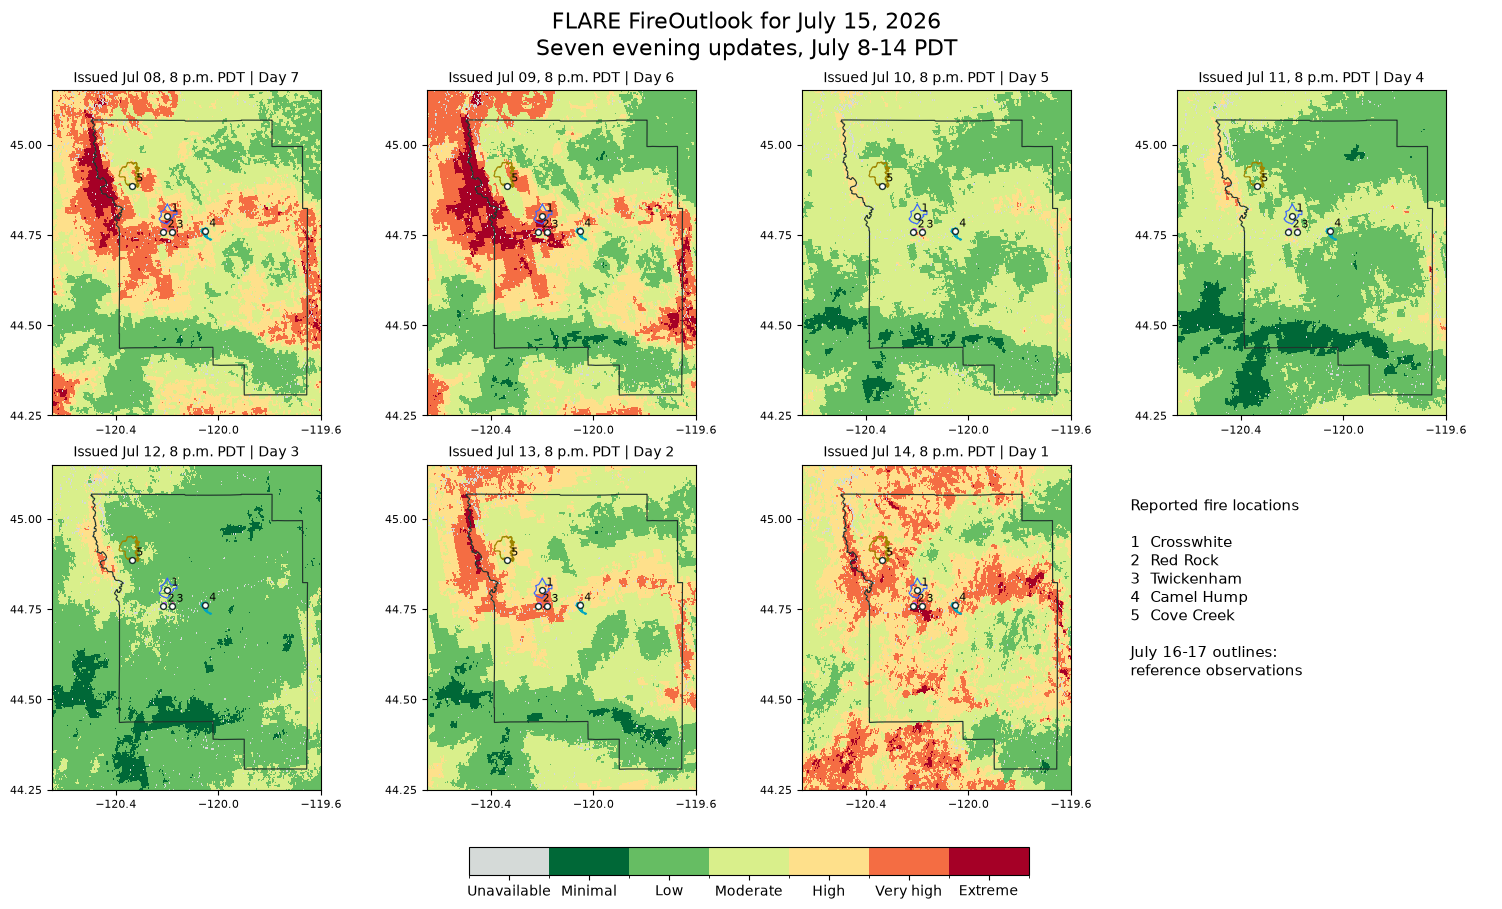

In [3]:
fig = plot_progression(ds)
fig.savefig(output / "july15_forecast_progression.png", dpi=140)
plt.show()

## 3. Follow the updates one at a time

This animation keeps July 15 fixed while advancing the issue date from July 8
to July 14. The full seven-panel figure above remains available for comparison.

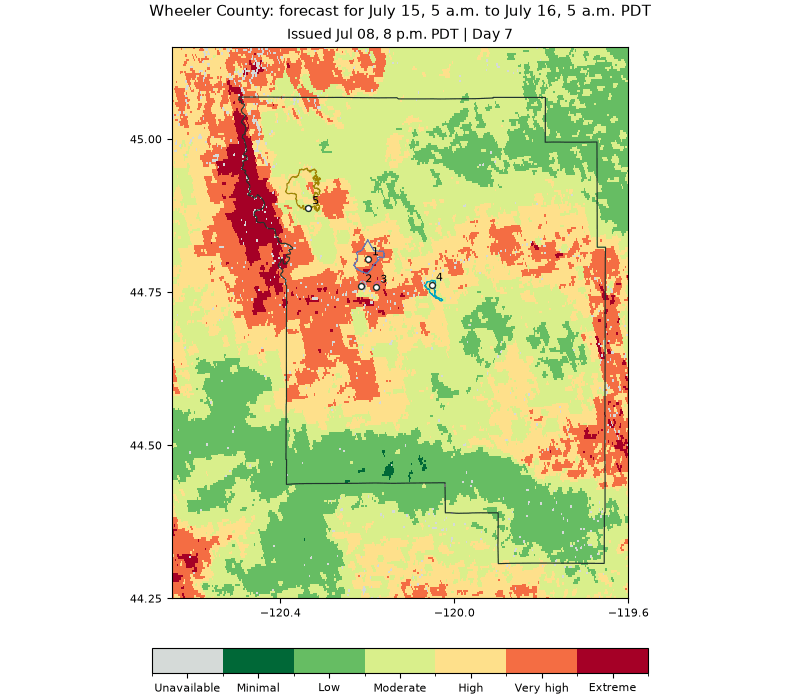

In [4]:
from matplotlib.animation import FuncAnimation, PillowWriter
fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
mesh = draw_update(ds, 0, ax, context)
fig.colorbar(mesh, ax=ax, orientation="horizontal", fraction=.045,
             ticks=range(7)).ax.set_xticklabels(LABELS, fontsize=8)
fig.suptitle("Wheeler County: forecast for July 15, 5 a.m. to July 16, 5 a.m. PDT", fontsize=11)
def animate(i):
    ax.clear()
    draw_update(ds, i, ax, context)
animation = FuncAnimation(fig, animate, frames=7, interval=1200, repeat=True)
animation.save(output / "july15_forecast_progression.gif", writer=PillowWriter(fps=1), dpi=100)
plt.close(fig)
display(Image(filename=str(output / "july15_forecast_progression.gif")))

## 4. How much of Wheeler County was High or above?

Recompute the county percentages from the bundled forecast pixels. Each pixel
center inside the Census county boundary contributes its source geodesic area.
The denominator includes all county pixel centers, including unavailable areas,
matching the presentation's calculation. Boundary pixels use center inclusion.
This is forecast danger area, not burned area.

,issued_PDT,forecast_day,county_high_or_above_pct,county_scored_pct
0,2026-07-08 20:00:00-07:00,7,40.00,99.07
1,2026-07-09 20:00:00-07:00,6,36.40,99.07
2,2026-07-10 20:00:00-07:00,5,2.81,99.07
3,2026-07-11 20:00:00-07:00,4,1.85,99.07
4,2026-07-12 20:00:00-07:00,3,1.17,99.07
5,2026-07-13 20:00:00-07:00,2,22.62,99.07
6,2026-07-14 20:00:00-07:00,1,52.01,99.07


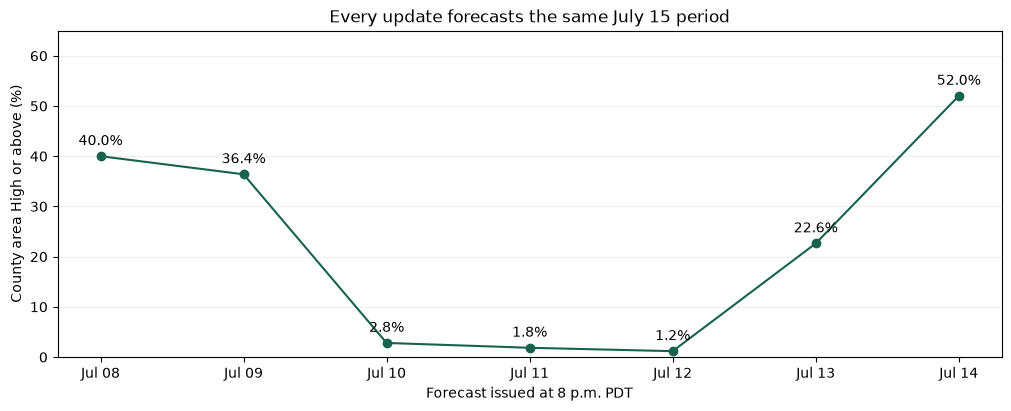

In [5]:
county = county_statistics(ds)
display(county[["issued_PDT", "forecast_day", "county_high_or_above_pct", "county_scored_pct"]].round(2))
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
labels = county.issued_PDT.dt.strftime("Jul %d").tolist()
ax.plot(range(7), county.county_high_or_above_pct, marker="o", color="#17624d")
for i, value in enumerate(county.county_high_or_above_pct):
    ax.annotate(f"{value:.1f}%", (i, value), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set(xticks=range(7), xticklabels=labels, ylim=(0, 65),
       xlabel="Forecast issued at 8 p.m. PDT", ylabel="County area High or above (%)",
       title="Every update forecasts the same July 15 period")
ax.grid(axis="y", alpha=.2)
plt.show()

## 5. Compare the five reported fire locations

For each origin, use the same nearest native-grid pixel across all seven
issuances. The table reports category names; the chart shows the underlying
indices. This examines changing forecast guidance at later reported fire
locations, rather than predicted ignition times or fire spread.

,Crosswhite,Red Rock,Twickenham,Camel Hump,Cove Creek
Issued at 8 p.m. PDT,,,,,
Jul 08,Very high,Very high,Very high,Moderate,Moderate
Jul 09,Very high,Extreme,Very high,Moderate,Moderate
Jul 10,Moderate,High,Moderate,Moderate,Moderate
Jul 11,Moderate,Moderate,Moderate,Low,Moderate
Jul 12,Moderate,Moderate,Low,Low,Low
Jul 13,High,Very high,Very high,Moderate,High
Jul 14,High,Very high,Very high,High,Very high


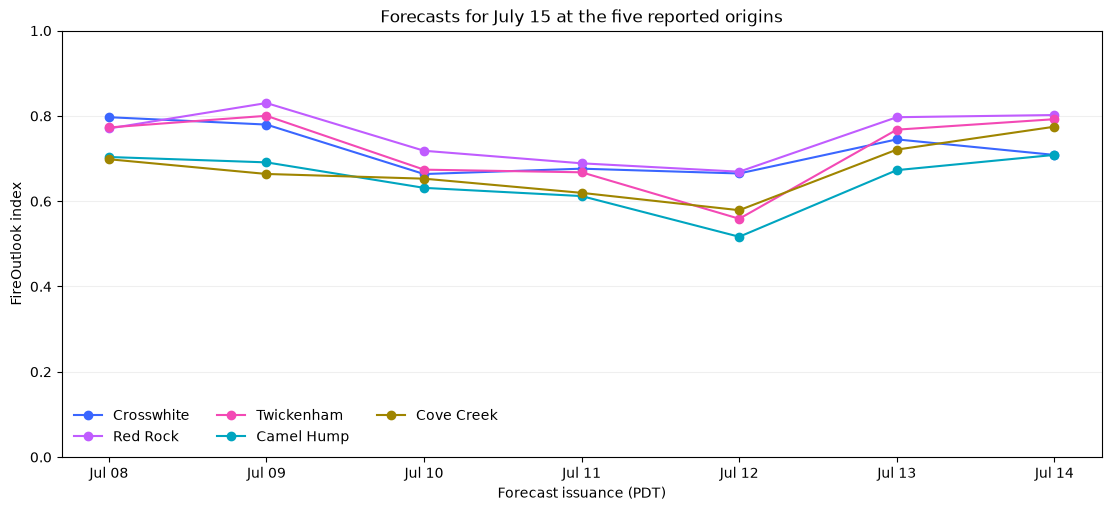

In [6]:
origins = [f for f in context["features"] if f["geometry"]["type"] == "Point"]
series = {}
for feature in origins:
    lon, lat = feature["geometry"]["coordinates"]
    values = point_forecast(ds, lat, lon)
    values["fire"] = feature["properties"]["name"]
    values["quality_notes"] = [", ".join(flag_names(ds, int(v))) or "None set"
                               for v in values.quality_flags]
    series[feature["properties"]["name"]] = values
comparison = pd.DataFrame({name: values.category.to_list() for name, values in series.items()},
                          index=pd.Index(labels, name="Issued at 8 p.m. PDT"))
display(comparison)
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for feature in origins:
    name = feature["properties"]["name"]
    ax.plot(range(7), series[name]["index"], marker="o", label=name, color=feature["properties"]["color"])
ax.set(xticks=range(7), xticklabels=labels, ylim=(0, 1), xlabel="Forecast issuance (PDT)",
       ylabel="FireOutlook index", title="Forecasts for July 15 at the five reported origins")
ax.legend(loc="lower left", ncol=3, frameon=False)
ax.grid(axis="y", alpha=.2)
plt.show()

## 6. Explore your own location and export results

Change the coordinate below to a location within the sample. The default is the
reported Crosswhite origin. The table preserves the selected pixel, distance
from the requested location, valid period, weather source, and quality flags.

In [7]:
latitude, longitude = 44.803333, -120.199167
point = point_forecast(ds, latitude, longitude)
display(point)
point.to_csv(output / "july15_selected_location.csv", index=False)
county.to_csv(output / "july15_county_progression.csv", index=False)
pd.concat(series.values(), ignore_index=True).to_csv(output / "july15_five_fire_locations.csv", index=False)
print("Saved figures and three CSV files in outlook/outputs")

,issued_PDT,issued_UTC,forecast_day,valid_start_PDT,valid_end_PDT,weather_cycle_UTC,weather_model,complete,index,category,category_code,quality_flags,latitude,longitude,distance_km
0,2026-07-08 20:00:00-07:00,2026-07-09 03:00:00+00:00,7,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-09 00:00:00+00:00,NBM,True,0.797065,Very high,5,64,44.801708,-120.19767,0.215986
1,2026-07-09 20:00:00-07:00,2026-07-10 03:00:00+00:00,6,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-10 00:00:00+00:00,NBM,True,0.779764,Very high,5,64,44.801708,-120.19767,0.215986
2,2026-07-10 20:00:00-07:00,2026-07-11 03:00:00+00:00,5,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-11 00:00:00+00:00,NBM,True,0.663719,Moderate,3,64,44.801708,-120.19767,0.215986
3,2026-07-11 20:00:00-07:00,2026-07-12 03:00:00+00:00,4,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-12 00:00:00+00:00,NBM,True,0.676341,Moderate,3,64,44.801708,-120.19767,0.215986
4,2026-07-12 20:00:00-07:00,2026-07-13 03:00:00+00:00,3,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-13 00:00:00+00:00,NBM,True,0.665069,Moderate,3,64,44.801708,-120.19767,0.215986
5,2026-07-13 20:00:00-07:00,2026-07-14 03:00:00+00:00,2,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-14 00:00:00+00:00,NBM,True,0.745026,High,4,64,44.801708,-120.19767,0.215986
6,2026-07-14 20:00:00-07:00,2026-07-15 03:00:00+00:00,1,2026-07-15 05:00:00-07:00,2026-07-16 05:00:00-07:00,2026-07-15 00:00:00+00:00,HRRR,True,0.708611,High,4,0,44.801708,-120.19767,0.215986


Saved figures and three CSV files in outlook/outputs


## Data and interpretation

This is a historical forecast replay from `FireOutlook2.0-hrrr1-nbm2to7-1`.
The July archive uses NBM on Day 2, unlike the later hybrid operational version.
Vegetation, snow support, and the pre-issue prior are frozen separately for each
issuance. The experiment's retained audit verified weather publication and
vegetation observation times before issue; historical prior receipt times were
not fully verified. Prior-application flags remain available for inspection.

Codes 1-6 mean Minimal through Extreme; code 0 means Unavailable. The five
category edges below come directly from this product. The index is an engineering
indicator, not a calibrated probability. Forecast changes are not themselves
evidence of increasing accuracy. This notebook makes no new skill claim.

County geometry: US Census TIGERweb, BAS 2026. Observed reference origins and
perimeters: retained NIFC/WFIGS NIFS records, July 16-17, with record timestamps
and IRWIN identifiers in the bundled GeoJSON. All maps and calculations use
the bundled source values, not pixels extracted from the presentation.

In [8]:
print("Category edges:", ds.attrs["category_edges"])
print("Weather policy:", ds.attrs["forecast_policy"])
ds.close()

Category edges: [0.44203031 0.61240017 0.70738232 0.75808346 0.81025106]
Weather policy: HRRR Day 1; NBM Days 2-7 experimental; vegetation, snow and prior frozen at issue
